# AP 155 Lab Exercise
---
## Exercise 11: Montecarlo Methods

_Instructions_:
- **Report Figures**:
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Delos Santos, Mico
- _Student No._: 2024-35117
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figure


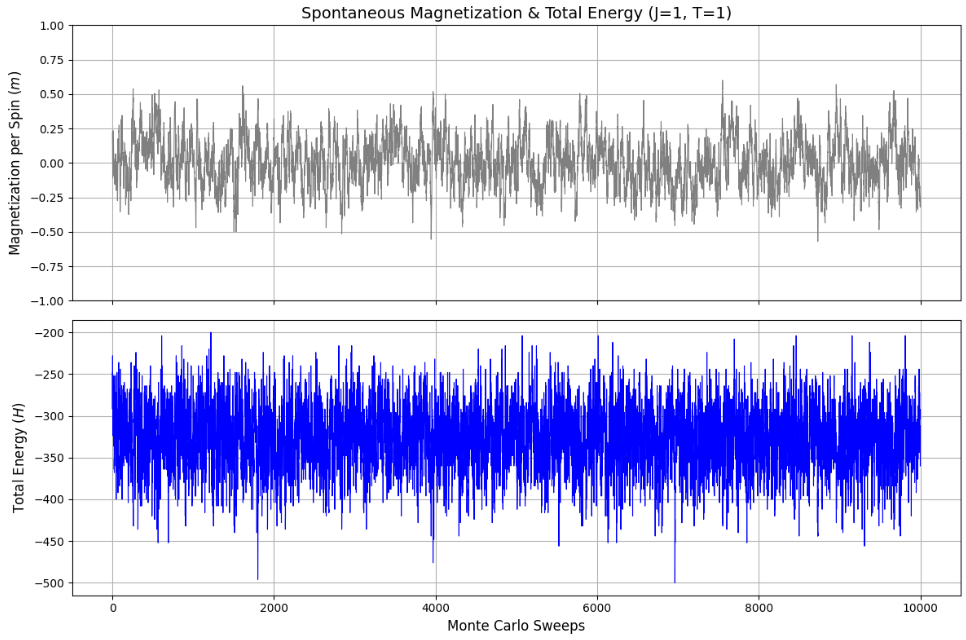
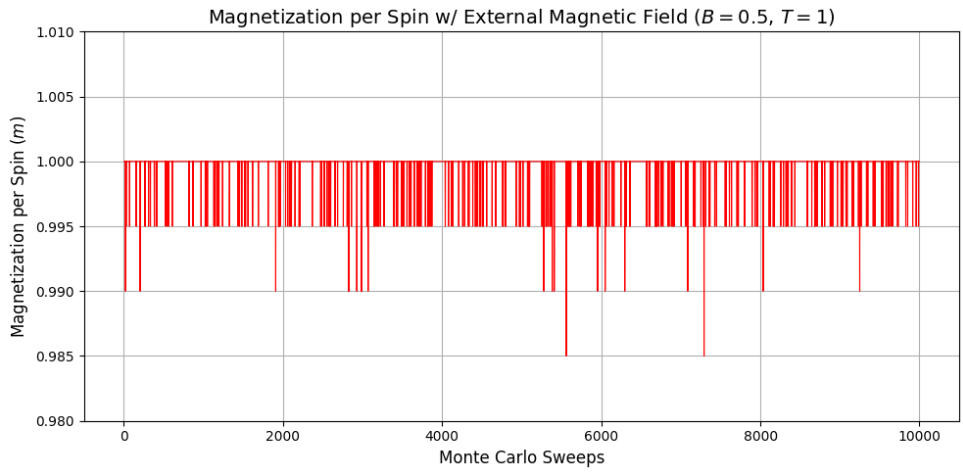
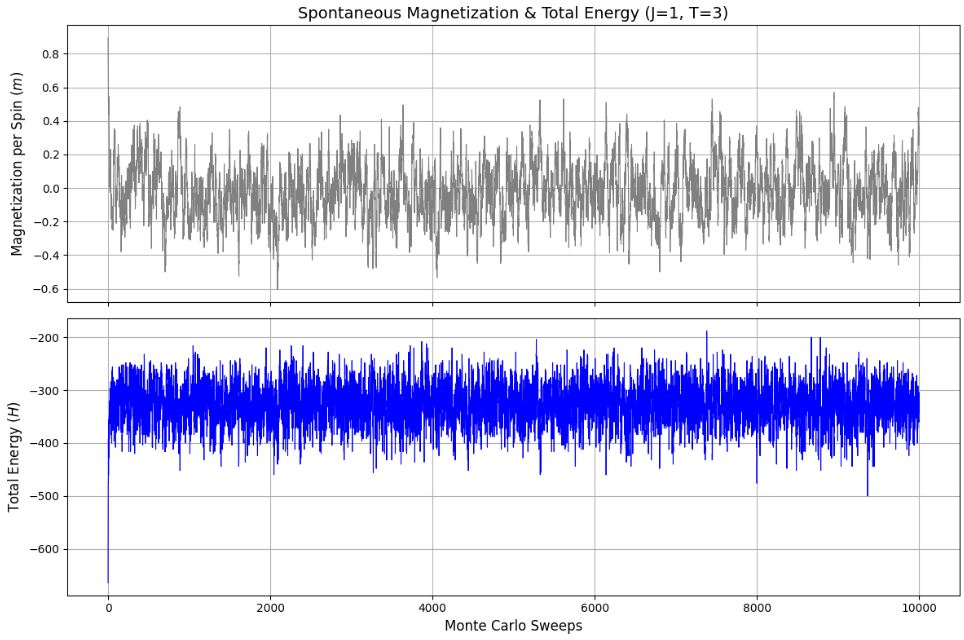
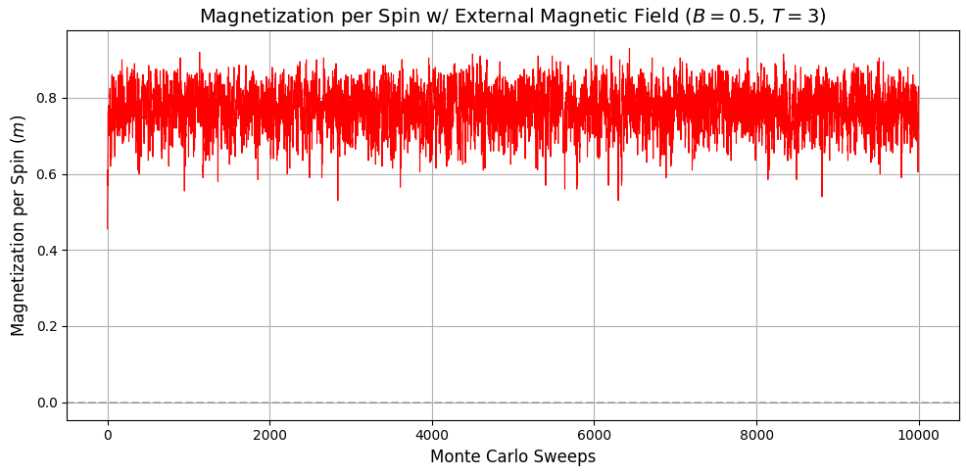

In [52]:
import base64
from IPython.display import HTML, display

figures = ["(1) orig_woB.png", "(2) orig_wB.png", "(3) T=3, woB.png", "(4) T=3, wB.png"]

html_output = ""
for f in figures:
    with open(f, "rb") as img:
        b64_data = base64.b64encode(img.read()).decode('utf-8')
        html_output += f"<h4>{f}</h4><img src='data:image/png;base64,{b64_data}' width='600'/><br><br>"

display(HTML(html_output))

### Report discussion

The figure 1 [(1) orig_woB] shows the "vanilla problem" where $J=T=k_B=1$ and $B=0$ for $N=10000$ sweeps. The setup models the Ising model under low temperature and wityhout an external magnetic field.

The gray represents the magnetization per spin $m$. As seen, it's stable on the range $y\in(-1,+1)$, noting that it is below $T_C$. $\textit{Initially, the magnetization is zero due to random spin mixing.}$

The blue represents the total energy $H$. As seen, it goes up and down in the range $y\in(-500,-200)$, a low stable energy. $\textit{For completely aligned lattice when  J>0, we get $-2N^2J$.}$

The figure 2 [(2) orig_wB] is the same w/ the setup in the "vanilla" but w/ external magnetic field $B$ of $B=0.5$.

As seen, $m$ flatlines closely at $y=1$, evem w/ $B$, the ;pw thermal energy $T$ is too low to help the system escape its initial state.

The figure 3 [(3) T=3, woB] shows what happens if the $T>T_C$, specifically $T=3$ but w/o $B$.

The gray represents $m$. As seen, it fluctuates between $y\in(-0.6,0.6)$. $\textit{Since $T>T_C$, the system develop spontaneous magnetization}$ Another thing to notice is, we can have $\textit{$+,-$ $m$. This happens due to spontaneous symmetry breaking}$.

The blue represents $H$, where it flactuates around the bound $y\in(-500, -200)$. This wide range and high energy shows the effect of higher $T$ that excited the spin flips and disordered nearest-neighbor configurations for $N=10000$. $\textit{The preferred spin orientation is determined by early stochastic fluctations.}$

The figure 4 [(4) T=3, wB] shows what happens if the $T>T_C$, specifically $T=3$ w/ $B$.

As seen, the fluctuations is not that similar to figure 3 as $B$ stabilizes it. This is because the external field $B=0.5$ forces spins to align w. the said field, polarize the spins. This now breaks the spatial symmetry, allowing aligned states energetically favorable.

### Other comments
- I was not able to attend the lab class, we were tasked to visit a museum in my GE class.

- The https://box.liknayan.com/ can't be reached. Did this mostly in colab-- w/ long executing time.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

---
## Section 2: Code

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import math

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

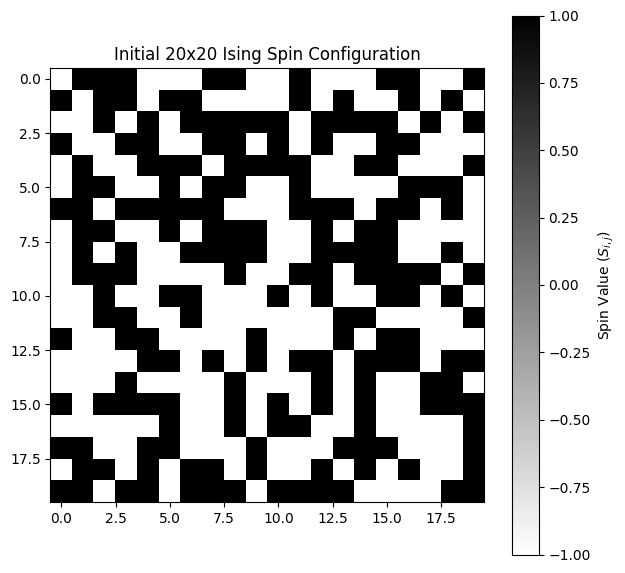

In [36]:
N = 20
lattice = np.random.choice([-1, 1], size = (N, N))

plt.figure(figsize=(7, 7))
plt.imshow(lattice, cmap='binary', interpolation = 'nearest')
plt.title(f"Initial 20x20 Ising Spin Configuration")
plt.colorbar(label="Spin Value ($S_{i, j}$)")
plt.show()

def total_energy(lattice, J):
    neighbor_sum = np.roll(lattice, -1, axis=0) + np.roll(lattice, -1, axis=1) #calc neighbor sum using BCs
    interaction_sum = lattice * neighbor_sum
    return -J * np.sum(interaction_sum)

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

In [37]:
J, k_B, T = 1, 1, 1
sweeps = 10000

def metropolis_sweep(lattice, J, T):
    N = lattice.shape[0]

    for (xy) in range(N*N):
        i = np.random.randint(0, N) #randomly select spin coord. (i, j)
        j = np.random.randint(0, N)
        spin = lattice[i,j]         #flip

        #sum of the 4 nearest neighbors using periodic BCs (% N)
        neighbor_sum = (lattice[(i + 1) % N, j] + lattice[(i - 1) % N, j] + lattice[i, (j + 1) % N] + lattice[i, (j - 1) % N])

        Delta_H = 2*spin * J*neighbor_sum #Del_H = 2S_{i,j} * J*sum

        #conditions-Metropolis
        if Delta_H <= 0:          #E decreases (or stays same), accept flip
            lattice[i,j] = -spin
        else:                     #accept flip w/ prob exp(-DelH/k_B T)
            if np.random.rand() < np.exp(-Delta_H / (k_B * T)):
                lattice[i,j] = -spin
    return lattice

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

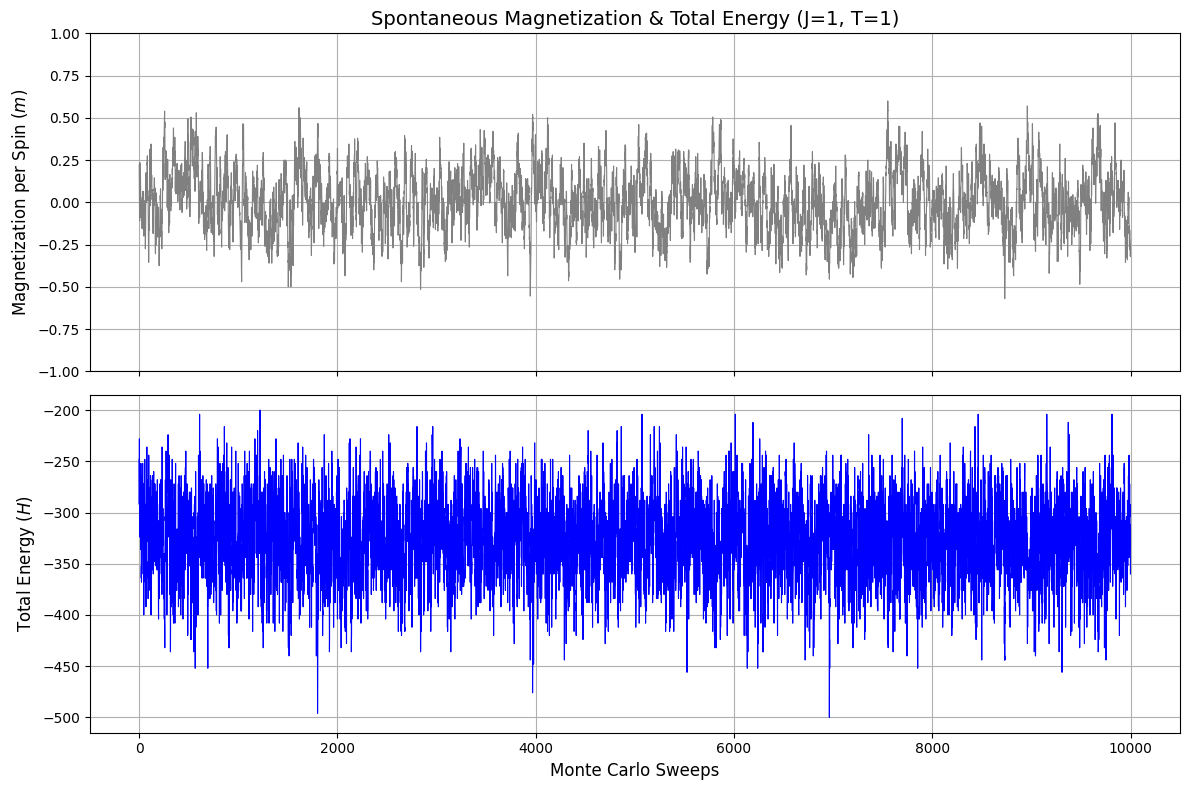

In [40]:
energies = []
magnetizations_spin = []

for sweep in range(sweeps):
    lattice = metropolis_sweep(lattice, J, T)
    E = total_energy(lattice, J)  #calc total E
    M = np.sum(lattice)           #calc m = M/N^2
    m = M / (N*N)
    energies.append(E)
    magnetizations_spin.append(m)

fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axs[0].plot(magnetizations_spin, color='gray', linewidth=0.8)
axs[0].set_ylabel("Magnetization per Spin ($m$)", fontsize=12)
axs[0].set_ylim(-1, 1)
axs[0].set_title("Spontaneous Magnetization & Total Energy (J=1, T=1)", fontsize=14)
axs[0].grid(True)

axs[1].plot(energies, color='blue', linewidth=0.8)
axs[1].set_xlabel("Monte Carlo Sweeps", fontsize=12)
axs[1].set_ylabel("Total Energy ($H$)", fontsize=12)
axs[1].grid(True)

plt.tight_layout()
plt.show()

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

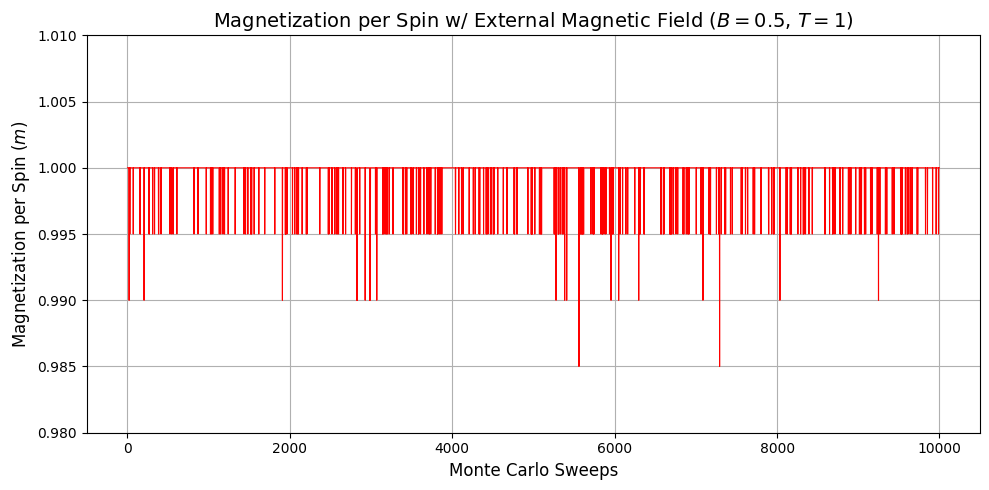

In [48]:
#compiling all codes previously; update and add B parameter
B = 0.5
J, k_B, T = 1, 1, 1
sweeps = 10000

def total_energy(lattice, J, B): ###...,B
    neighbor_sum = (np.roll(lattice, -1, axis=0) + np.roll(lattice, 1, axis=0)) + (np.roll(lattice, -1, axis=1) + np.roll(lattice, 1, axis=1)) #calc neighbor sum using BCs

    interaction_energy = -J * np.sum(lattice * neighbor_sum) / 2 #avoids double count: /2
    Bfield_energy = -B * np.sum(lattice)

    return interaction_energy + Bfield_energy

def metropolis_sweep(lattice, J, T, B): ###...,B
    N = lattice.shape[0]

    for (xy) in range(N*N):
        i = np.random.randint(0, N) #randomly select spin coord. (i, j)
        j = np.random.randint(0, N)
        spin = lattice[i,j]         #flip

        #sum of the 4 nearest neighbors using periodic BCs (% N)
        neighbor_sum = (lattice[(i + 1) % N, j] + lattice[(i - 1) % N, j] + lattice[i, (j + 1) % N] + lattice[i, (j - 1) % N])

        ### +B
        Delta_H = 2*spin * (J*neighbor_sum + B) #Del_H = 2S_{i,j} * (J*sum + B)

        #conditions-Metropolis
        if Delta_H <= 0:          #E decreases (or stays same), accept flip
            lattice[i,j] = -spin
        else:                     #accept flip w/ prob exp(-DelH/k_B T)
            if np.random.rand() < np.exp(-Delta_H / (k_B * T)):
                lattice[i,j] = -spin
    return lattice

energies = []
magnetizations_spin = []

for sweep in range(sweeps):
    lattice = metropolis_sweep(lattice, J, T, B) ###...,B
    E = total_energy(lattice, J, B)              #calc total E
    M = np.sum(lattice)                          #calc m = M/N^2
    m = M / (N*N)
    energies.append(E)
    magnetizations_spin.append(m)

plt.figure(figsize=(10, 5))
plt.plot(magnetizations_spin, color='red', linewidth=0.8)
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.title(f"Magnetization per Spin w/ External Magnetic Field ($B = {B}$, $T = {T}$)", fontsize=14)
plt.xlabel("Monte Carlo Sweeps", fontsize=12)
plt.ylim(0.98, 1.01)
plt.ylabel("Magnetization per Spin ($m$)", fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

# Exercise: The Two-Dimensional Ising Model

## 5. Critical Temperature

The critical temperature of the 2D Ising model is

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

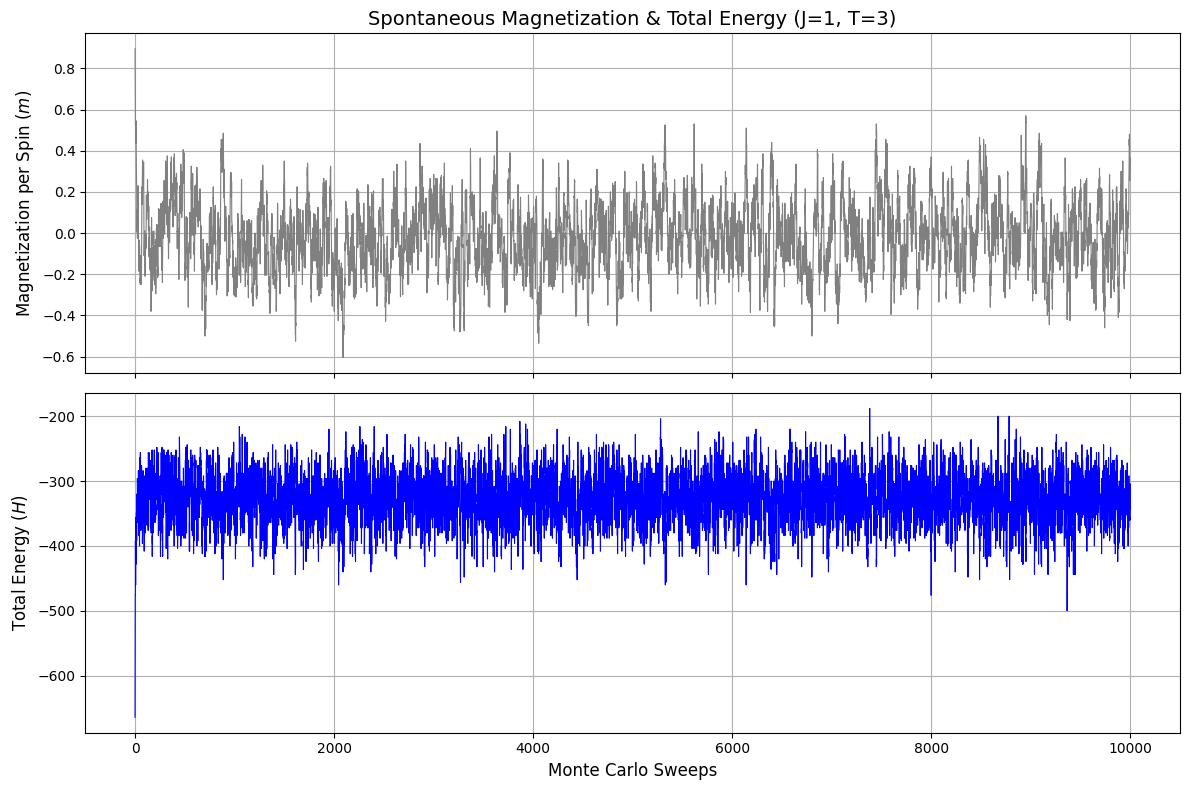

In [44]:
#above T_C, but w/o B

J, k_B, T = 1, 1, 3
sweeps = 10000

def total_energy(lattice, J):
    neighbor_sum = np.roll(lattice, -1, axis=0) + np.roll(lattice, -1, axis=1) #calc neighbor sum using BCs
    interaction_sum = lattice * neighbor_sum
    return -J * np.sum(interaction_sum)

def metropolis_sweep(lattice, J, T):
    N = lattice.shape[0]

    for (xy) in range(N*N):
        i = np.random.randint(0, N) #randomly select spin coord. (i, j)
        j = np.random.randint(0, N)
        spin = lattice[i,j]         #flip

        #sum of the 4 nearest neighbors using periodic BCs (% N)
        neighbor_sum = (lattice[(i + 1) % N, j] + lattice[(i - 1) % N, j] + lattice[i, (j + 1) % N] + lattice[i, (j - 1) % N])

        Delta_H = 2*spin * J*neighbor_sum #Del_H = 2S_{i,j} * J*sum

        #conditions-Metropolis
        if Delta_H <= 0:          #E decreases (or stays same), accept flip
            lattice[i,j] = -spin
        else:                     #accept flip w/ prob exp(-DelH/k_B T)
            if np.random.rand() < np.exp(-Delta_H / (k_B * T)):
                lattice[i,j] = -spin
    return lattice

energies = []
magnetizations_spin = []

for sweep in range(sweeps):
    lattice = metropolis_sweep(lattice, J, T)
    E = total_energy(lattice, J)  #calc total E
    M = np.sum(lattice)           #calc m = M/N^2
    m = M / (N*N)
    energies.append(E)
    magnetizations_spin.append(m)

fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axs[0].plot(magnetizations_spin, color='gray', linewidth=0.8)
axs[0].set_ylabel("Magnetization per Spin ($m$)", fontsize=12)
axs[0].set_title("Spontaneous Magnetization & Total Energy (J=1, T=3)", fontsize=14)
axs[0].grid(True)

axs[1].plot(energies, color='blue', linewidth=0.8)
axs[1].set_xlabel("Monte Carlo Sweeps", fontsize=12)
axs[1].set_ylabel("Total Energy ($H$)", fontsize=12)
axs[1].grid(True)

plt.tight_layout()
plt.show()

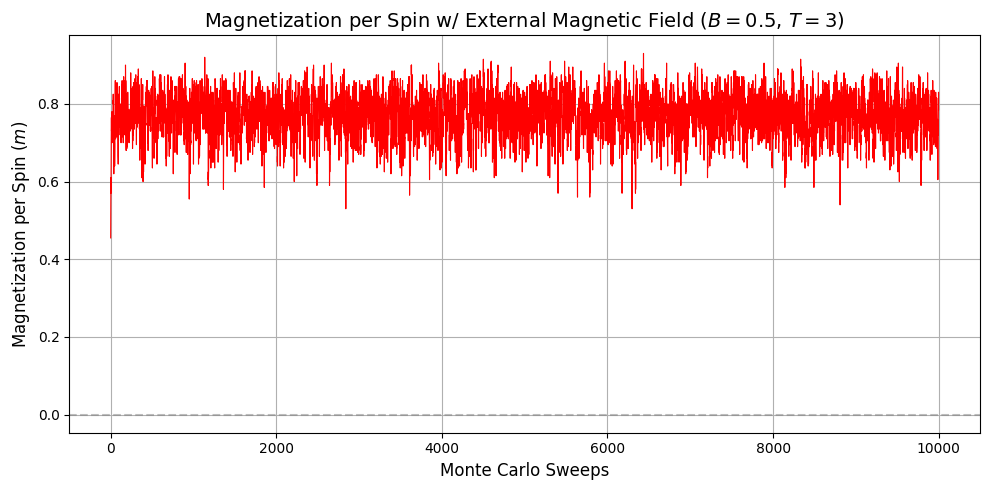

In [ ]:
#above T_C w/ B

B = 0.5
J, k_B, T = 1, 1, 3
sweeps = 10000

def total_energy(lattice, J, B): ###...,B
    neighbor_sum = (np.roll(lattice, -1, axis=0) + np.roll(lattice, 1, axis=0)) + (np.roll(lattice, -1, axis=1) + np.roll(lattice, 1, axis=1)) #calc neighbor sum using BCs

    interaction_energy = -J * np.sum(lattice * neighbor_sum) / 2 #avoids double count: /2
    Bfield_energy = -B * np.sum(lattice)

    return interaction_energy + Bfield_energy

def metropolis_sweep(lattice, J, T, B): ###...,B
    N = lattice.shape[0]

    for (xy) in range(N*N):
        i = np.random.randint(0, N) #randomly select spin coord. (i, j)
        j = np.random.randint(0, N)
        spin = lattice[i,j]         #flip

        #sum of the 4 nearest neighbors using periodic BCs (% N)
        neighbor_sum = (lattice[(i + 1) % N, j] + lattice[(i - 1) % N, j] + lattice[i, (j + 1) % N] + lattice[i, (j - 1) % N])

        ### +B
        Delta_H = 2*spin * (J*neighbor_sum + B) #Del_H = 2S_{i,j} * (J*sum + B)

        #conditions-Metropolis
        if Delta_H <= 0:          #E decreases (or stays same), accept flip
            lattice[i,j] = -spin
        else:                     #accept flip w/ prob exp(-DelH/k_B T)
            if np.random.rand() < np.exp(-Delta_H / (k_B * T)):
                lattice[i,j] = -spin
    return lattice

energies = []
magnetizations_spin = []

for sweep in range(sweeps):
    lattice = metropolis_sweep(lattice, J, T, B) ###...,B
    E = total_energy(lattice, J, B)              #calc total E
    M = np.sum(lattice)                          #calc m = M/N^2
    m = M / (N*N)
    energies.append(E)
    magnetizations_spin.append(m)

plt.figure(figsize=(10, 5))
plt.plot(magnetizations_spin, color='red', linewidth=0.8)
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.title(f"Magnetization per Spin w/ External Magnetic Field ($B = {B}$, $T = {T}$)", fontsize=14)
plt.xlabel("Monte Carlo Sweeps", fontsize=12)
plt.ylabel("Magnetization per Spin ($m$)", fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()